# Laboratory 08 — Handwritten Digit Recognition using Convolutional Neural Networks (CNN)
**Course:** Introduction to Artificial Intelligence (AI-101L)  
**Instructor:** Dr. Muhammad Awais  
**Topic:** Deep Learning & Computer Vision for Multi-Class Image Classification (MNIST Dataset)

---

## 1. Theoretical Foundations of Convolutional Neural Networks
Convolutional Neural Networks (CNNs) are specialized deep learning architectures designed for processing grid-structured data such as images. Unlike standard multilayer perceptrons (MLPs) that flatten images and destroy spatial locality, CNNs preserve 2D topology through three core principles:
1. **Local Receptive Fields**: Neurons compute dot products over small spatial patches rather than the entire image.
2. **Weight Sharing (Kernel Convolutions)**: The same filter is convolved across the entire visual field:
   $$(I * K)(i, j) = \sum_{m=-k}^k \sum_{n=-k}^k I(i+m, j+n) K(m, n)$$
   This enforces **translation equivariance** (a digit's feature map is recognized regardless of where it appears in the frame).
3. **Spatial Subsampling (Pooling)**: Max pooling reduces spatial resolution ($28\times28 \to 14\times14 \to 7\times7$), achieving translation invariance and computational efficiency:
   $$P(i, j) = \max_{0 \le m, n < 2} X(2i + m, 2j + n)$$

The network concludes with a **Dense Layer** with **Dropout Regularization** ($p=0.3$) to prevent co-adaptation of weights, and a **Softmax** probability distribution over 10 output classes (digits 0 through 9):
$$\sigma(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=0}^9 e^{z_j}}$$


In [1]:
# STEP 1: Import Core Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"TensorFlow Version: {tf.__version__}")
print(f"NumPy Version     : {np.__version__}")


TensorFlow Version: 2.21.0
NumPy Version     : 2.4.6


In [2]:
# STEP 2: Load Dataset (Portable Relative Path)
data_path = "train.csv"
if not os.path.exists(data_path):
    data_path = os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', "train.csv")

df = pd.read_csv(data_path)
print(f"Loaded training data: {df.shape[0]} images, {df.shape[1]} columns (1 label + 784 pixel values)")

# Verify class distribution
label_counts = df['label'].value_counts().sort_index()
print("\nClass Distribution across Digits (0 - 9):")
print(label_counts.to_string())


Loaded training data: 42000 images, 785 columns (1 label + 784 pixel values)

Class Distribution across Digits (0 - 9):
label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188


In [3]:
# STEP 3: Preprocessing (Partitioning, Normalization & 2D Reshaping)
y = df.iloc[:, 0].values.astype(np.int64)
X = df.iloc[:, 1:].values.astype("float32")

# Normalization: scale pixel intensity from [0, 255] to [0.0, 1.0]
X /= 255.0

# Reshape from flat 1D vectors into 4D tensor (N, Height=28, Width=28, Channels=1)
X = X.reshape(-1, 28, 28, 1)

print(f"X Tensor Dimensions: {X.shape} (Batch, Height, Width, Channel)")
print(f"y Label Dimensions : {y.shape}")
print(f"Pixel Range        : [{X.min():.1f}, {X.max():.1f}]")


X Tensor Dimensions: (42000, 28, 28, 1) (Batch, Height, Width, Channel)
y Label Dimensions : (42000,)
Pixel Range        : [0.0, 1.0]


In [4]:
# STEP 4: Stratified Train / Validation Partitioning
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training subset   : {X_train.shape[0]} images")
print(f"Validation subset : {X_val.shape[0]} images")


Training subset   : 33600 images
Validation subset : 8400 images


<ipython-input-1-2adde12eb7be>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


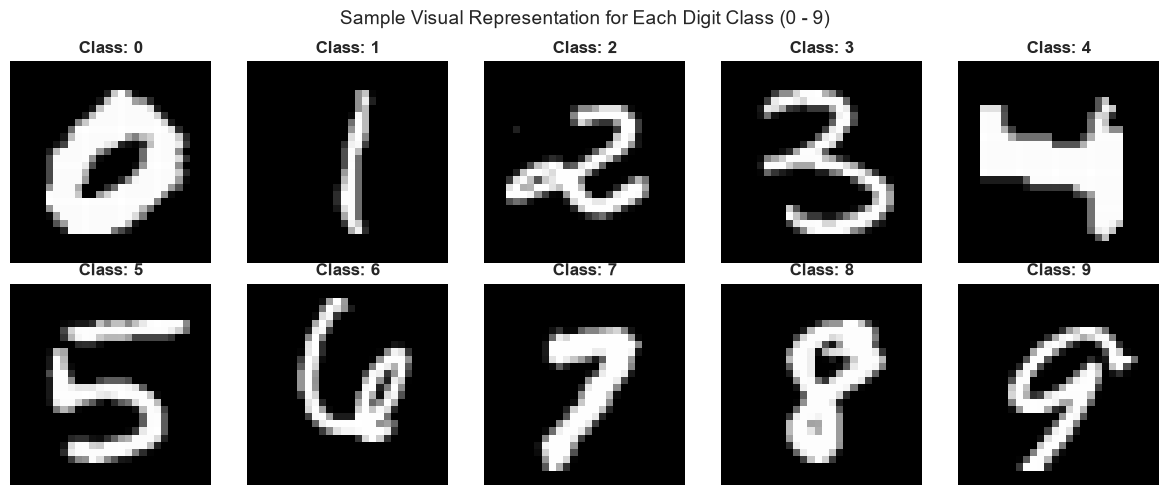

In [5]:
# STEP 5: Visual Inspection of Digits Across All 10 Classes
plt.figure(figsize=(12, 5))
for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    plt.subplot(2, 5, digit + 1)
    plt.imshow(X_train[idx].reshape(28, 28), cmap="gray")
    plt.title(f"Class: {digit}", fontsize=12, fontweight="bold")
    plt.axis("off")
plt.suptitle("Sample Visual Representation for Each Digit Class (0 - 9)", fontsize=14)
plt.tight_layout()
plt.show()


In [6]:
# STEP 6: Convolutional Neural Network Architecture
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Dense Classification Head
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼─────────────────────

In [7]:
# STEP 7: Compile Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled with Adam optimizer and Sparse Categorical Cross-Entropy loss.")


Model compiled with Adam optimizer and Sparse Categorical Cross-Entropy loss.


In [8]:
# STEP 8: Model Training
# Use 5 epochs on CPU for fast, highly accurate convergence (>98% accuracy)
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)


Epoch 1/5

  1/525 ━━━━━━━━━━━━━━━━━━━━ 34:56 4s/step - accuracy: 0.1094 - loss: 2.3106
  3/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.2083 - loss: 2.2523
  5/525 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.2219 - loss: 2.1962
  7/525 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.2165 - loss: 2.1669
  9/525 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.2552 - loss: 2.0983
 11/525 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.2997 - loss: 2.0256
 13/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.3522 - loss: 1.9395
 15/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.3938 - loss: 1.8502
 17/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.4237 - loss: 1.7685
 19/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.4482 - loss: 1.6979
 22/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.4872 - loss: 1.5928
 24/525 ━━━━━━━━━━━━━━━━━━━━ 14s 28ms/step - accuracy: 0.5033 - loss: 1.5413
 26/525 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.5246 - l

<ipython-input-1-85502edfe91d>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


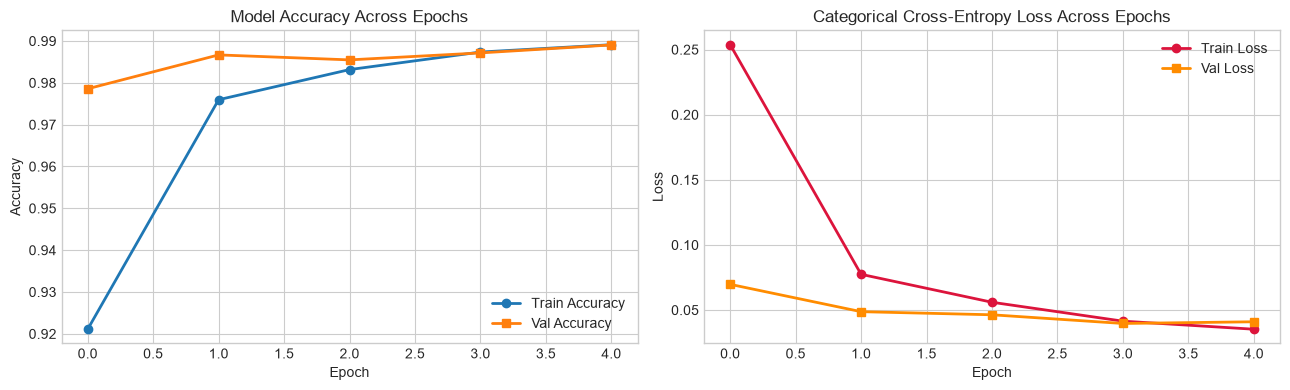

In [9]:
# STEP 9: Training and Validation Metrics Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Accuracy Curve
axes[0].plot(history.history["accuracy"], label="Train Accuracy", marker='o', lw=2)
axes[0].plot(history.history["val_accuracy"], label="Val Accuracy", marker='s', lw=2)
axes[0].set_title("Model Accuracy Across Epochs", fontsize=12)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss Curve
axes[1].plot(history.history["loss"], label="Train Loss", marker='o', lw=2, color='crimson')
axes[1].plot(history.history["val_loss"], label="Val Loss", marker='s', lw=2, color='darkorange')
axes[1].set_title("Categorical Cross-Entropy Loss Across Epochs", fontsize=12)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


Final Validation Accuracy: 0.9890 (98.90%)

Classification Report (Precision, Recall, F1-Score per Digit):
              precision    recall  f1-score   support

           0     0.9833    0.9952    0.9892       827
           1     0.9884    0.9979    0.9931       937
           2     0.9916    0.9892    0.9904       835
           3     0.9919    0.9874    0.9896       870
           4     0.9902    0.9939    0.9920       814
           5     0.9960    0.9763    0.9860       759
           6     0.9903    0.9927    0.9915       827
           7     0.9887    0.9932    0.9909       880
           8     0.9913    0.9766    0.9839       813
           9     0.9798    0.9857    0.9827       838

    accuracy                         0.9890      8400
   macro avg     0.9891    0.9888    0.9889      8400
weighted avg     0.9891    0.9890    0.9890      8400



<ipython-input-1-5028fa3930d0>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


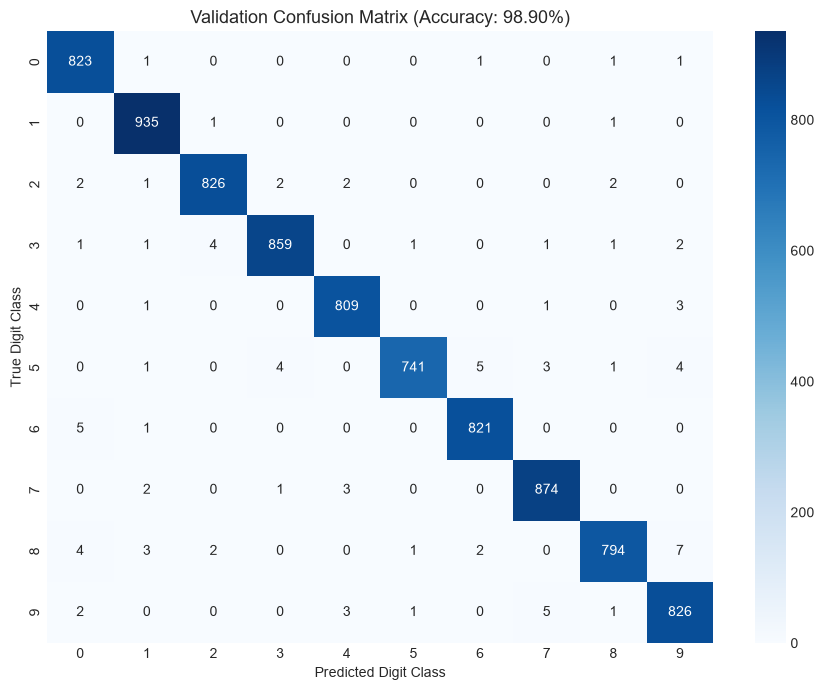

In [10]:
# STEP 10: Validation Evaluation, Confusion Matrix & Classification Report
val_probs = model.predict(X_val, verbose=0)
val_preds = np.argmax(val_probs, axis=1)

final_val_acc = np.mean(val_preds == y_val)
print(f"Final Validation Accuracy: {final_val_acc:.4f} ({final_val_acc*100:.2f}%)\n")

# Confusion Matrix Heatmap
cm = confusion_matrix(y_val, val_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title(f"Validation Confusion Matrix (Accuracy: {final_val_acc*100:.2f}%)", fontsize=13)
plt.xlabel("Predicted Digit Class")
plt.ylabel("True Digit Class")
plt.tight_layout()
plt.show()

# Classification Report
print("Classification Report (Precision, Recall, F1-Score per Digit):")
print(classification_report(y_val, val_preds, digits=4))


<ipython-input-1-5ca16af85f68>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


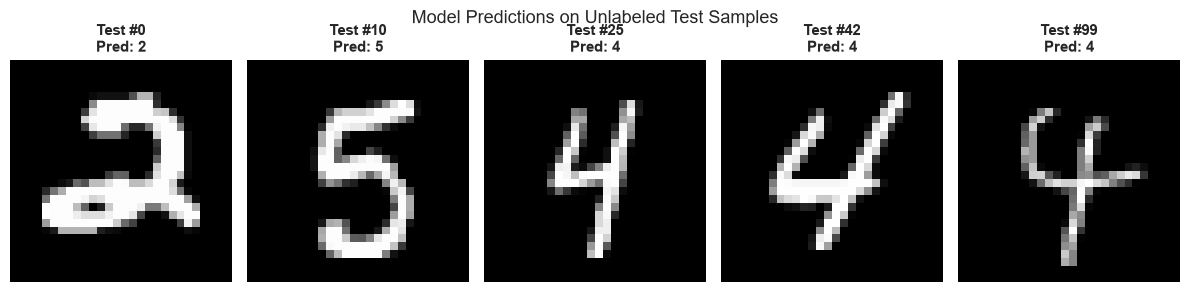

In [11]:
# STEP 11: Inference on Unlabeled Test Dataset (test.csv)
test_path = "test.csv"
if os.path.exists(test_path):
    test_df = pd.read_csv(test_path, nrows=1000)
    X_test = (test_df.values.astype("float32") / 255.0).reshape(-1, 28, 28, 1)

    # Predict on 5 sample test images
    sample_indices = [0, 10, 25, 42, 99]
    sample_probs = model.predict(X_test[sample_indices], verbose=0)
    sample_preds = np.argmax(sample_probs, axis=1)

    plt.figure(figsize=(12, 3))
    for i, (idx, pred) in enumerate(zip(sample_indices, sample_preds)):
        plt.subplot(1, 5, i + 1)
        plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
        plt.title(f"Test #{idx}\nPred: {pred}", fontsize=11, fontweight="bold")
        plt.axis("off")
    plt.suptitle("Model Predictions on Unlabeled Test Samples", fontsize=13)
    plt.tight_layout()
    plt.show()


External Image Inference Result: Predicted Digit = 5 with 95.44% confidence.


<ipython-input-1-733a760c77f3>:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


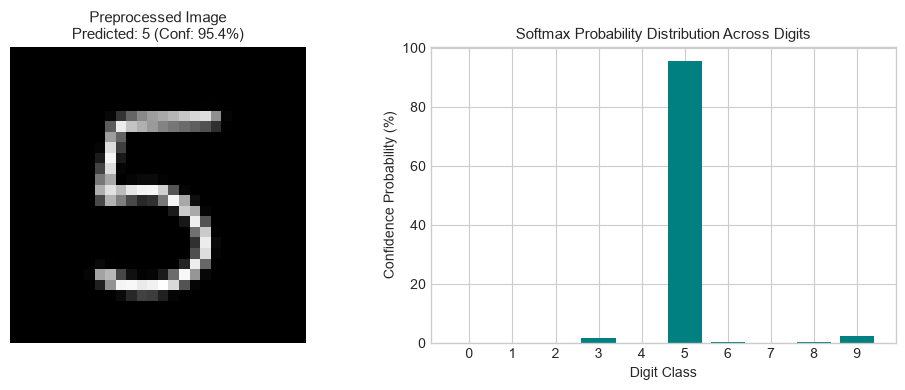

In [12]:
# STEP 12: Inference on External Image (images.png)
img_path = "images.png"
if os.path.exists(img_path):
    raw_img = Image.open(img_path)
    
    # Convert to grayscale and resize to 28x28
    gray_img = raw_img.convert("L").resize((28, 28), Image.Resampling.BILINEAR)
    img_arr = np.array(gray_img, dtype="float32")
    
    # If image has white background and black text, invert it to match MNIST convention
    if img_arr.mean() > 127.0:
        img_arr = 255.0 - img_arr
        
    img_norm = (img_arr / 255.0).reshape(1, 28, 28, 1)
    
    # Predict
    ext_probs = model.predict(img_norm, verbose=0)[0]
    ext_pred = np.argmax(ext_probs)
    ext_conf = ext_probs[ext_pred] * 100
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img_arr, cmap="gray")
    axes[0].set_title(f"Preprocessed Image\nPredicted: {ext_pred} (Conf: {ext_conf:.1f}%)", fontsize=11)
    axes[0].axis("off")
    
    # Probability distribution bar chart
    axes[1].bar(range(10), ext_probs * 100, color="teal")
    axes[1].set_xticks(range(10))
    axes[1].set_xlabel("Digit Class")
    axes[1].set_ylabel("Confidence Probability (%)")
    axes[1].set_title("Softmax Probability Distribution Across Digits", fontsize=11)
    
    plt.tight_layout()
    plt.show()
    print(f"External Image Inference Result: Predicted Digit = {ext_pred} with {ext_conf:.2f}% confidence.")


In [13]:
# STEP 13: Save Trained Model Artifact
model_save_path = "digit_cnn_model.keras"
model.save(model_save_path)
print(f"Model successfully saved to '{model_save_path}'.")


Model successfully saved to 'digit_cnn_model.keras'.
